# 晶圆缺陷分类：降维是否真的有帮助？
## WM-811K · 可复现实验记录

本 Notebook 完成课程作业的实验部分：数据检查、预处理说明、训练/验证/测试划分、PCA、PCA+LDA、分类、准确率曲线、结果解释，以及与原项目 CNN 的同样本比较。**本轮不撰写英文报告。**

**阅读方法**：按顺序阅读每个文字单元，再看下一格代码和输出。已经保存真实执行结果；在 Jupyter 中选择 **Kernel → Restart Kernel and Run All Cells** 可重新运行。无需 GPU、PyTorch、网络或原项目目录，约 2.2 MB 的处理后数据已包含在 `data/` 中。

**研究问题**：4096 个像素特征压缩后，哪些分类器/维数能保留或改善泛化表现？压缩损失、类别不平衡与少数类表现之间有什么关系？所有结果均由程序计算，不保证降维一定有效。

**来源**：[Kaggle WM-811K](https://www.kaggle.com/datasets/qingyi/wm811k-wafer-map)。原始数据文献：M.-J. Wu, J.-S. R. Jang, J.-L. Chen, “Wafer Map Failure Pattern Recognition and Similarity Ranking for Large-Scale Data Sets,” IEEE Transactions on Semiconductor Manufacturing, 28(1), 1–12, 2015。


### 1. 环境和路径

使用 Python + NumPy/pandas + scikit-learn + Matplotlib。原 CNN 仅以已有预测参与比较，本次没有重新训练 CNN。随机种子固定；不同库版本/BLAS 的数值细节仍可能造成细微差异。

In [1]:
from pathlib import Path
import sys, json, hashlib, time, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "study.py").exists():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("请从 wafer_dimensionality_study 文件夹或其 notebooks 子文件夹打开 Notebook")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.study import CLASSES, CONFIG, fit_development, evaluate_frozen
from src.prepare_data import preprocess
(ROOT / "figures").mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
print("Project:", ROOT.name)
print("Python:", platform.python_version())
print("Protocol:", json.dumps(CONFIG, indent=2))

<LOCAL_PATH> is not a writable directory


Matplotlib created a temporary cache directory at /var/folders/sn/5pn8hqlj4_zbm3ctc6qtbggh0000gn/T/matplotlib-xxxo7e5s because there was an issue with the default path (<LOCAL_PATH> it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Matplotlib is building the font cache; this may take a moment.


Project: wafer_dimensionality_study
Python: 3.12.14
Protocol: {
  "seed": 20261021,
  "pca_dimensions": [
    1,
    2,
    4,
    8,
    16,
    32,
    64,
    128
  ],
  "lda_dimensions": [
    1,
    2,
    3,
    4,
    5,
    6,
    7,
    8
  ],
  "lda_input_dimensions": 128,
  "classifiers": [
    "3NN",
    "NCM"
  ],
  "selection_metric": "validation_macro_f1",
  "bootstrap_repetitions": 2000,
  "pca_whiten": false,
  "pca_randomized_iter": 5
}


### 2. 数据是怎样得到的？

原始文件包含 811,457 条记录，只有 172,950 张有标签。`none` 是有效的无明显模式类别，**不是缺失标签**。每个格点的值是 0（背景）、1（通过测试的 die）、2（失效 die），不是显微照片的灰度。

沿用原项目 `train_manifest.csv`、`validation_manifest.csv` 和 `test_manifest.csv` 的边界，三者批次相互隔离。为控制运行时间，在**各集合内部**按类别固定随机抽样：训练每类最多 500，验证最多 100，测试最多 200；不足时全部保留。不是在全数据中重新打散分组。

随后根据最终 64×64 输入的 SHA-256 去掉完全重复的图像，优先保留训练，再验证，再测试。去重是输入数据检查，没有根据预测正确率删样本，也没有补采样以追求更好的结果。它只保证此子集输入不重复，并不宣称原 CNN 的完整训练集也经过了相同去重。

`data/manifest.csv` 保留原始行号、批次、类别和输入哈希；`data/audit.json` 记录来源和校验和。原始文件的读取与抽样代码见 `src/prepare_data.py`。

In [2]:
data = np.load(ROOT / "data" / "study_data.npz", allow_pickle=False)
audit = json.loads((ROOT / "data" / "audit.json").read_text())
manifest = pd.read_csv(ROOT / "data" / "manifest.csv")
assert hashlib.file_digest(open(ROOT / "data" / "study_data.npz", "rb"), "sha256").hexdigest() == audit["subset_sha256"]
counts = pd.crosstab(manifest.failure_type, manifest.dataset_split).reindex(CLASSES)
display(counts)
display(pd.DataFrame([{ "split": s, **{k:v for k,v in audit[s].items() if k != "classes"}} for s in ["train", "validation", "test"]]))

dataset_split,test,train,validation
failure_type,,,
Center,199,500,100
Donut,146,327,82
Edge-Loc,199,500,100
Edge-Ring,199,500,100
Loc,200,500,100
Near-full,89,43,9
Random,188,487,100
Scratch,197,400,100
none,199,500,100


,split,before_dedup,after_dedup,removed_duplicate_images,lots
0,train,3758,3757,1,2339
1,validation,792,791,1,501
2,test,1641,1616,25,1151


### 3. 预处理与高维输入

与原 CNN 一致：先在中心补零成正方形，保持晶圆的长宽比例；再用 nearest 插值到 64×64；最后除以 2，得到 0、0.5、1。NumPy 的索引按原 PyTorch `nearest` 的 floor 坐标规则实现，**没有引入 PyTorch 依赖**。这些是固定规则，不从测试数据学习。

之后展平成 4096 维向量。**展平不是降维**；PCA/LDA 才是本实验的降维。像素单位一致，本实验不逐像素 z-score，以免低方差边缘位置被过度放大。PCA 的中心化均值只从训练数据学习。

下面的样例按训练集原始索引顺序取中间位置，没有根据模型效果挑选。细划痕在缩放后可能变弱，这是预处理限制，不能假设每个标签的图都像理想示意图。

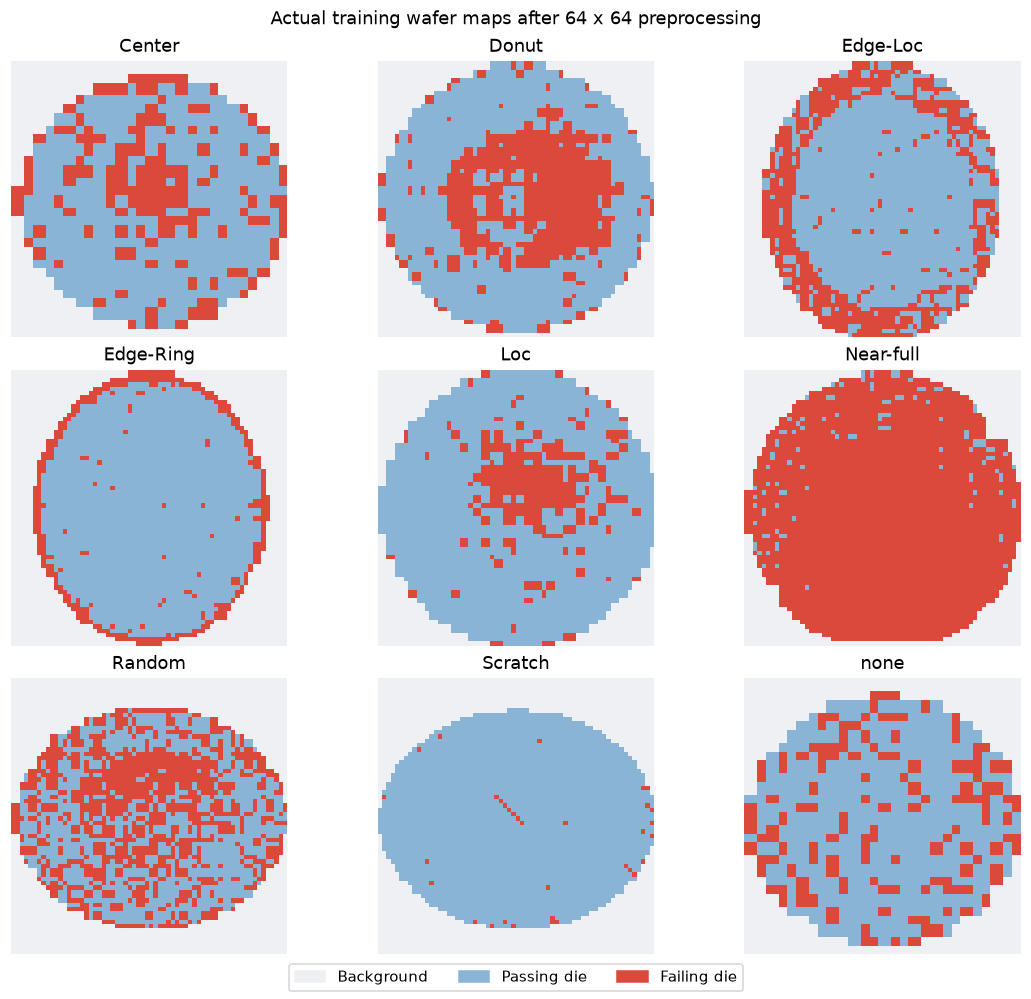

In [3]:
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
cmap = ListedColormap(["#eef0f4", "#8ab4d5", "#db493b"])
norm = BoundaryNorm([-0.25, 0.25, 0.75, 1.25], 3)
fig, axes = plt.subplots(3, 3, figsize=(10, 9), layout="constrained")
for ax, name in zip(axes.ravel(), CLASSES):
    cls = CLASSES.index(name)
    ix = np.flatnonzero(data["y_train"] == cls)
    i = ix[len(ix)//2]
    ax.imshow(data["X_train"][i].reshape(64,64), cmap=cmap, norm=norm, interpolation="nearest")
    ax.set_title(name); ax.axis("off")
fig.legend(handles=[Patch(color=cmap(i),label=s) for i,s in enumerate(["Background", "Passing die", "Failing die"])],loc="outside lower center",ncols=3)
fig.suptitle("Actual training wafer maps after 64 x 64 preprocessing")
fig.savefig(ROOT / "figures" / "01_examples.png", dpi=180)
plt.show()

### 4. 划分与泄漏检查

这一步检查：样本原始索引不重叠、批次不重叠、预处理后的输入哈希不重复、类别编码一致。正式模型使用训练集拟合，验证集选择维数和模型家族；最终测试仅做评分，不会回头修改参数。

**重要背景**：原项目已经评估过官方测试集。本研究是在同一个既有测试基准上的回顾性比较，不称为全新、从未观察过的外部测试。子集经过类别限额抽样，其准确率也不代表产线自然类别比例。

In [4]:
splits = {s: manifest[manifest.dataset_split == s] for s in ["train", "validation", "test"]}
for i, a in enumerate(splits):
    assert data[f"X_{a}"].shape[1] == 4096
    assert set(np.unique(data[f"y_{a}"])) == set(range(9))
    assert np.isfinite(data[f"X_{a}"]).all()
    for b in list(splits)[i+1:]:
        for col in ["source_index", "lotName", "image_sha256"]:
            assert not set(splits[a][col]) & set(splits[b][col]), (a,b,col)
assert not manifest.image_sha256.duplicated().any()
# 用非方形人工输入检查补零和 floor-nearest 坐标；不涉及模型性能。
example = np.array([[0,1,2],[2,1,0]], dtype=np.float32)
processed = preprocess(example, size=6)
assert processed.shape == (6,6) and set(np.unique(processed)) <= {0.,.5,1.}
print("PASS: source/lot/input separation; all 9 classes; finite 4096-D inputs; preprocessing check.")
print("Train/validation/test:", [len(splits[s]) for s in splits])

PASS: source/lot/input separation; all 9 classes; finite 4096-D inputs; preprocessing check.
Train/validation/test: [3757, 791, 1616]


### 5. 方法：PCA 与 LDA 分别优化什么？

**PCA（无监督）**：训练数据中心化后，寻找方差最大的正交方向。投影为 $z=(x-\mu)W_d$。保留大方差可以减小重建误差，**不保证分类信息最多**。本实验不白化，以免把低方差成分放大。

**LDA（监督）**：利用训练标签，寻找类间分离较大、类内变化较小的方向。对应广义特征值问题 $S_b w=\lambda S_w w$。标准 LDA 有效维数最多为 $C-1=8$。

原始输入 4096 维，训练样本数量少于 4096，直接求类内散度矩阵的逆不可靠。因此先用 PCA 降到固定 128 维，再用 SVD-LDA 提取 1–8 维。PCA=128 是测试前固定的中间设置，**不是经典 Fisherface 为保留全部训练秩而设定的维数**，可能损失有用信息。

**分类器**：主要使用固定的欧氏距离 3-NN（均匀投票）；再以最近类均值 NCM 作简单线性基线。对所有表示保持相同的分类器定义，避免把分类器调参收益误认为降维收益。NCM 通过每类均值自然平等比较各类；不做 SMOTE、图像增强或复杂模型搜索。

预先固定网格：PCA = 1,2,4,8,16,32,64,128；PCA128+LDA = 1,…,8；不降维=4096。两个分类器共 34 个配置。**按验证 Macro F1 选择**每个家族的维数及全局候选；准确率仍是课程要求的主要曲线之一。

参考：X. Jiang, “Linear Subspace Learning-Based Dimensionality Reduction,” IEEE Signal Processing Magazine, 28(2), 16–26, 2011。课堂 Topic 8 的关键区别是重建目标与判别目标不同，准确率是否改善必须由实验验证。

In [5]:
# 此函数不读取测试数组，只对 train 拟合，对 validation 评分。
bundle, validation_scores = fit_development(data, ROOT)
display(validation_scores.sort_values("macro_f1", ascending=False).head(12).round(4))
selection = json.loads((ROOT / "results" / "frozen_selection.json").read_text())
display(Markdown(f"**已冻结的全局候选：{selection['method']} / {selection['classifier']} / {selection['dimension']} 维。**"))

<LOCAL_PATH> UserWarning: Could not find the number of physical cores for the following reason:
invalid literal for int() with base 10: ''
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "<LOCAL_PATH>", line 264, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_darwin()
                         ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "<LOCAL_PATH>", line 420, in _count_physical_cores_darwin
    return int(cpu_info)
           ^^^^^^^^^^^^^
<LOCAL_PATH> UserWarning: self.within_class_std_dev_ has at least 1 zero standard deviation.Inputs within the same classes for at least 1 feature are identical.
  warnings.warn(


Development complete in 0.49 s; validation-selected configuration: {'method': 'PCA', 'classifier': '3NN', 'dimension': 16, 'accuracy': 0.7838179519595448, 'balanced_accuracy': 0.8082926829268293, 'macro_f1': 0.7990022916384151}


,method,classifier,dimension,accuracy,balanced_accuracy,macro_f1
6,PCA,3NN,16,0.7838,0.8083,0.7990
8,PCA,3NN,64,0.7686,0.7832,0.7784
7,PCA,3NN,32,0.7699,0.7846,0.7776
9,PCA,3NN,128,0.7522,0.7685,0.7655
5,PCA,3NN,8,0.7459,0.7640,0.7604
24,PCA+LDA,3NN,7,0.7244,0.7451,0.7438
25,PCA+LDA,3NN,8,0.7231,0.7327,0.7368
4,PCA,3NN,4,0.7054,0.7284,0.7250
23,PCA+LDA,3NN,6,0.7004,0.7232,0.7246
22,PCA+LDA,3NN,5,0.6877,0.7126,0.7104


**已冻结的全局候选：PCA / 3NN / 16 维。**

### 6. 看验证结果与方差保留率

这部分仍未使用测试结果选参数。验证曲线可以用于挑维数，但验证样本较少，Near-full 只有少量样本，最优点可能不稳定。解释时应关注曲线趋势和平台，不把单个最高点当成普遍规律。

方差保留率仅反映重建目标；它与分类分数并不是同一指标。

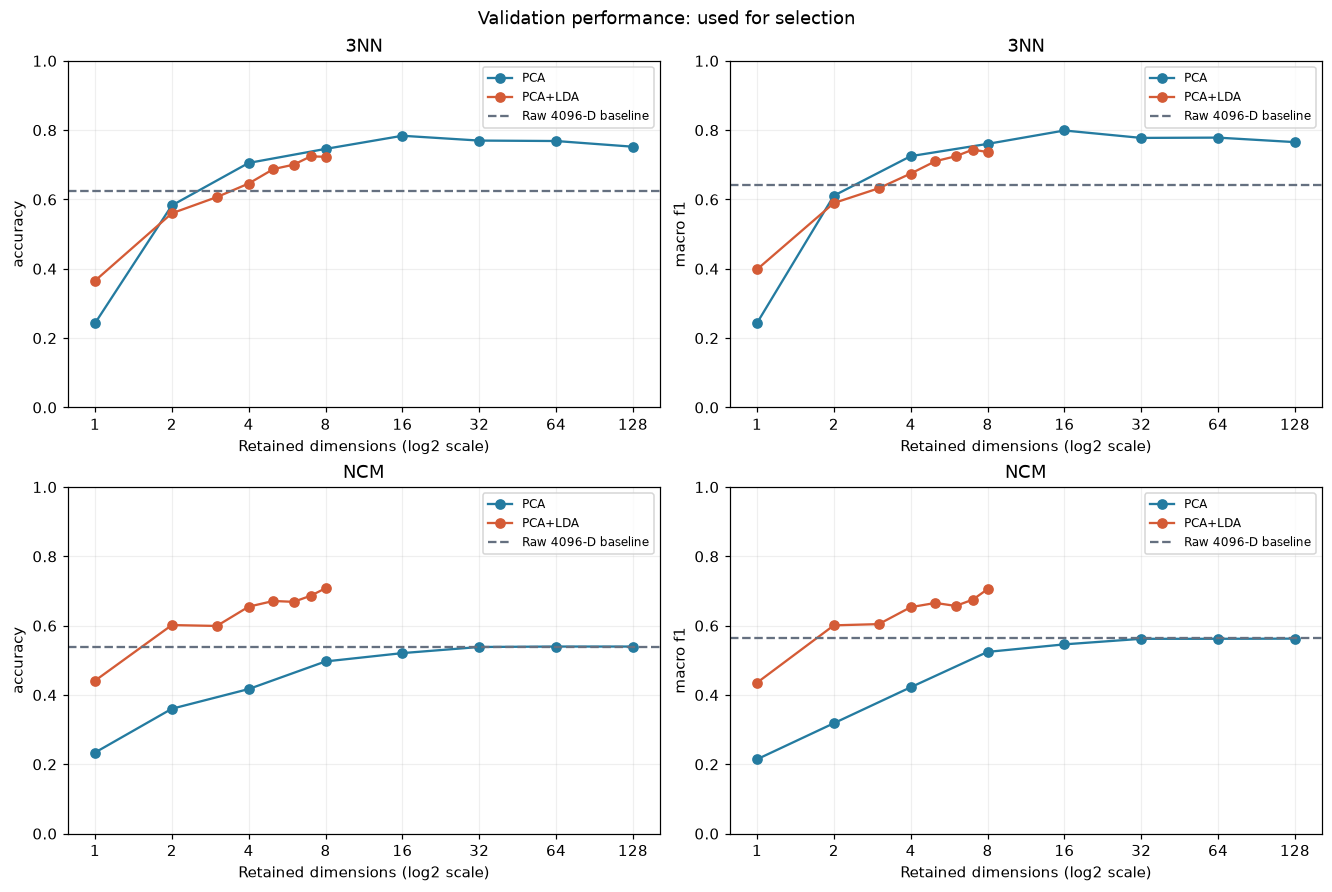

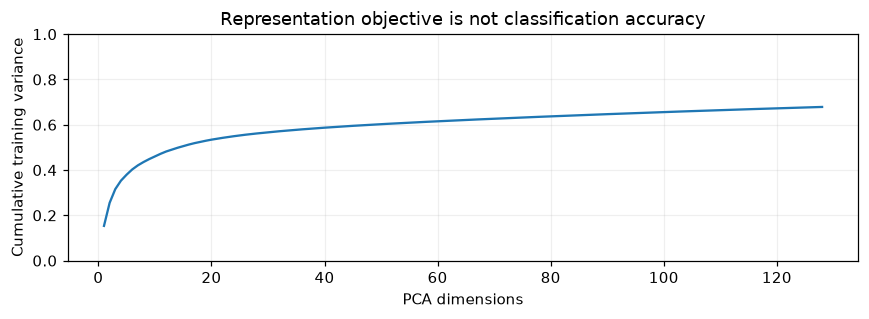

In [6]:
def curve_plot(frame, filename, title):
    fig, axes = plt.subplots(2,2,figsize=(12,8),layout="constrained")
    colors={"PCA":"#247ba0","PCA+LDA":"#d45b36"}
    for row, clf in enumerate(CONFIG["classifiers"]):
        sub=frame[frame.classifier==clf]
        for col, metric in enumerate(["accuracy","macro_f1"]):
            ax=axes[row,col]
            for method in ["PCA","PCA+LDA"]:
                q=sub[sub.method==method].sort_values("dimension")
                ax.plot(q.dimension, q[metric], "o-", label=method,color=colors[method])
            raw=float(sub[sub.method=="Raw"][metric].iloc[0])
            ax.axhline(raw,ls="--",color="#657080",label="Raw 4096-D baseline")
            ax.set_xscale("log",base=2);ax.set_xticks([1,2,4,8,16,32,64,128],labels=[1,2,4,8,16,32,64,128])
            ax.set_ylim(0,1);ax.set_xlabel("Retained dimensions (log2 scale)")
            ax.set_ylabel(metric.replace("_"," "));ax.set_title(clf);ax.grid(alpha=.2);ax.legend(fontsize=8)
    fig.suptitle(title);fig.savefig(ROOT/"figures"/filename,dpi=180);plt.show()
curve_plot(validation_scores,"02_validation_curves.png","Validation performance: used for selection")
fig,ax=plt.subplots(figsize=(8,3))
ax.plot(np.arange(1,129),np.cumsum(bundle["pca"].explained_variance_ratio_))
ax.set(xlabel="PCA dimensions",ylabel="Cumulative training variance",ylim=(0,1),title="Representation objective is not classification accuracy")
ax.grid(alpha=.2);fig.tight_layout();fig.savefig(ROOT/"figures"/"03_pca_variance.png",dpi=180);plt.show()

### 7. 冻结后评价测试集

现在才对预先定义的网格计算测试曲线，用于作业要求的趋势分析。**不得改用测试曲线上分数最高的点来替换验证集选择。** 下表每个家族的维数均由验证集决定。

原 CNN 使用原项目保存的预测，逐条核对同一 `source_index` 和真实标签；原 CNN 训练样本更多，本研究不是等训练预算的架构比较。表中 CNN 的 64 是其池化后特征维数，不代表本次向 CNN 加入了降维，也不与 PCA 的维数含义完全相同。

指标：Accuracy 是总体正确比例；Balanced Accuracy 是各类召回率的平均；Macro F1 是各类 F1 的平均，减少多数类掩盖问题。

{
  "selected_on_validation": {
    "method": "PCA",
    "classifier": "3NN",
    "dimension": 16,
    "accuracy": 0.7838179519595448,
    "balanced_accuracy": 0.8082926829268293,
    "macro_f1": 0.7990022916384151
  },
  "selected_test": {
    "accuracy": 0.39913366336633666,
    "balanced_accuracy": 0.4182107993697128,
    "macro_f1": 0.4347271850943046
  },
  "cnn_common_test": {
    "accuracy": 0.359529702970297,
    "balanced_accuracy": 0.3857236298803165,
    "macro_f1": 0.34811541415658437
  },
  "macro_f1_delta": 0.08661177093772021,
  "macro_f1_delta_ci95": [
    0.06359153841675334,
    0.10993984963510521
  ],
  "balanced_accuracy_delta": 0.032487169489396284,
  "integration_eligible": true,
  "bootstrap": "paired class-stratified percentile bootstrap; sample uncertainty only, not lot-level or training uncertainty",
  "inference_median_ms_per_sample": 0.008177499985322356,
  "timing_batch_size": 100,
  "inference_note": "Includes PCA/LDA and classifier, excludes image prepro

,method,classifier,dimension,accuracy,balanced_accuracy,macro_f1
1,PCA+LDA,3NN,7,0.3960,0.4203,0.4492
0,PCA,3NN,16,0.3991,0.4182,0.4347
2,PCA+LDA,NCM,8,0.3094,0.3476,0.3571
6,Original CNN,saved predictions,64,0.3595,0.3857,0.3481
5,PCA,NCM,128,0.3379,0.3714,0.3430
4,Raw,NCM,4096,0.3360,0.3698,0.3421
3,Raw,3NN,4096,0.2741,0.3109,0.2938


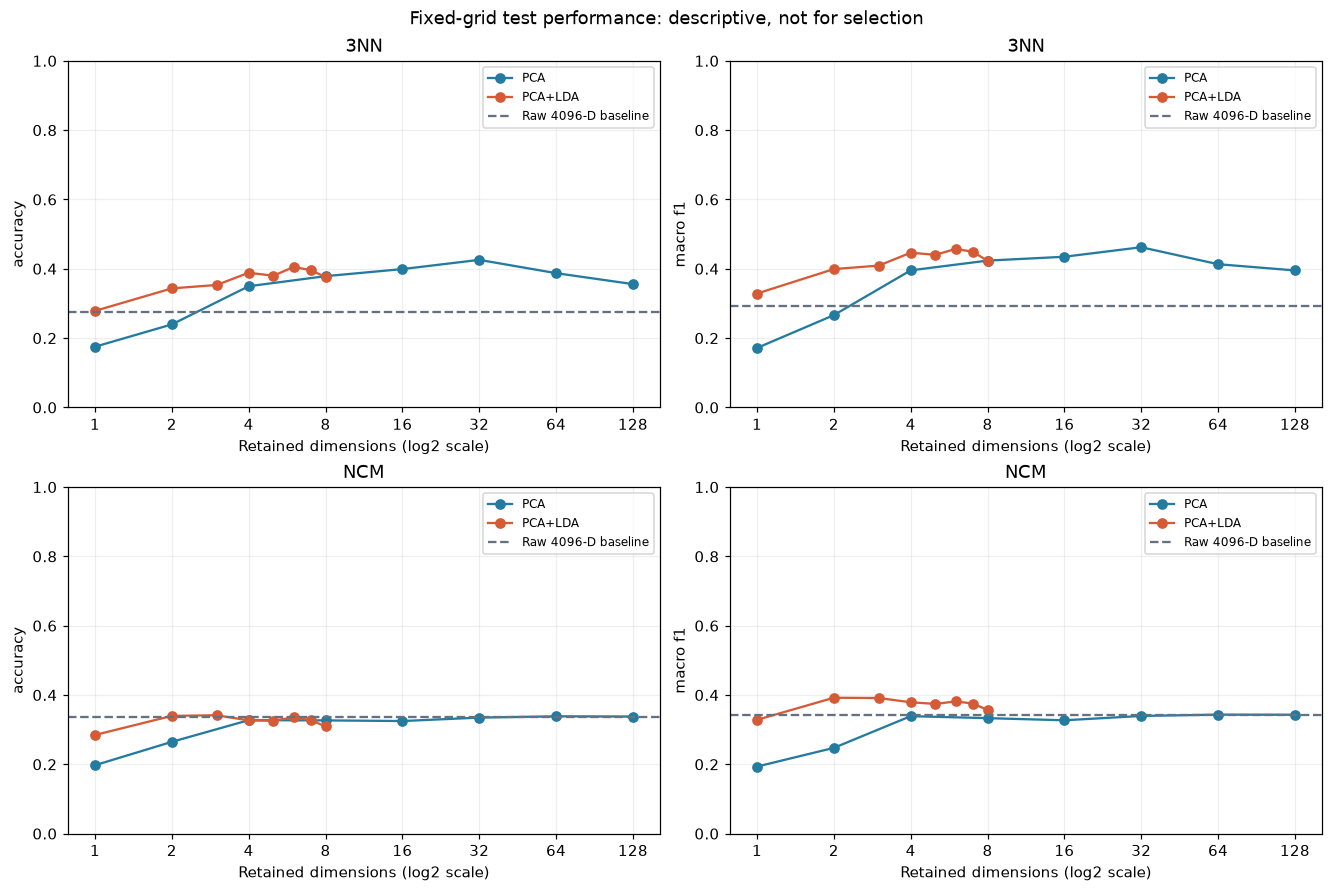

**验证选定方案的测试结果**：accuracy = 0.3991; balanced_accuracy = 0.4182; macro_f1 = 0.4347

In [7]:
test_scores, comparison, summary = evaluate_frozen(data, bundle, ROOT)
display(comparison.sort_values("macro_f1",ascending=False).round(4))
curve_plot(test_scores,"04_test_curves.png","Fixed-grid test performance: descriptive, not for selection")
display(Markdown("**验证选定方案的测试结果**：" + "; ".join(f"{k} = {v:.4f}" for k,v in summary["selected_test"].items())))

### 8. 哪些类别改善，哪些仍然困难？

只看总体准确率不够。以下比较全局验证候选和原 CNN 在同一测试子集上的逐类 F1 与混淆矩阵。行是真实类别，列是预测类别；每行归一化后，对角线就是该类别召回率。

,baseline_F1,CNN_F1,baseline_recall,CNN_recall,support,F1_delta
Center,0.4946,0.0656,0.4573,0.0503,199,0.4290
Donut,0.1875,0.0133,0.1233,0.0068,146,0.1742
Edge-Loc,0.3022,0.3243,0.4070,0.3015,199,-0.0221
Edge-Ring,0.5409,0.7327,0.3819,0.6131,199,-0.1918
Loc,0.2428,0.0356,0.2950,0.0200,200,0.2072
Near-full,0.8780,0.9180,0.8090,0.9438,89,-0.0400
Random,0.7590,0.6531,0.7287,0.5106,188,0.1059
Scratch,0.3022,0.0467,0.3858,0.0254,197,0.2555
none,0.2053,0.3437,0.1759,1.0000,199,-0.1384


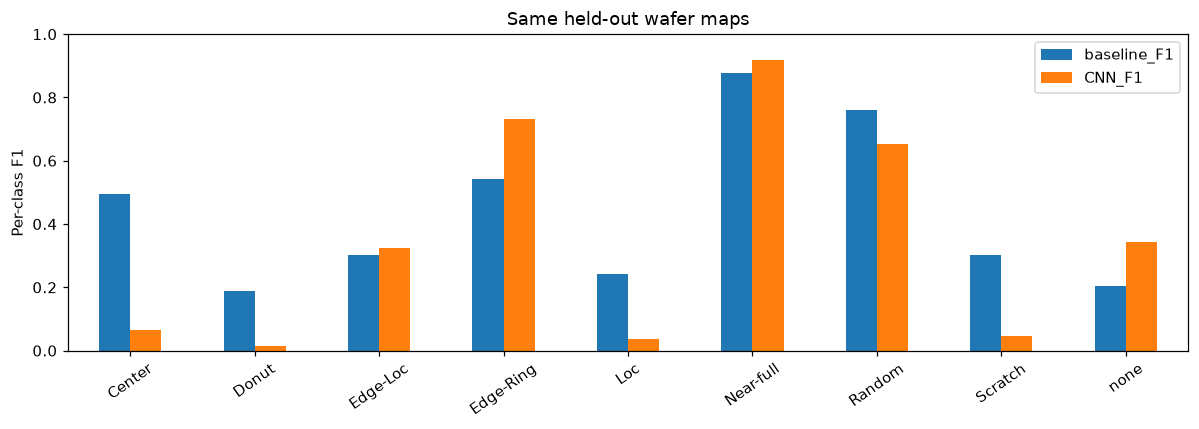

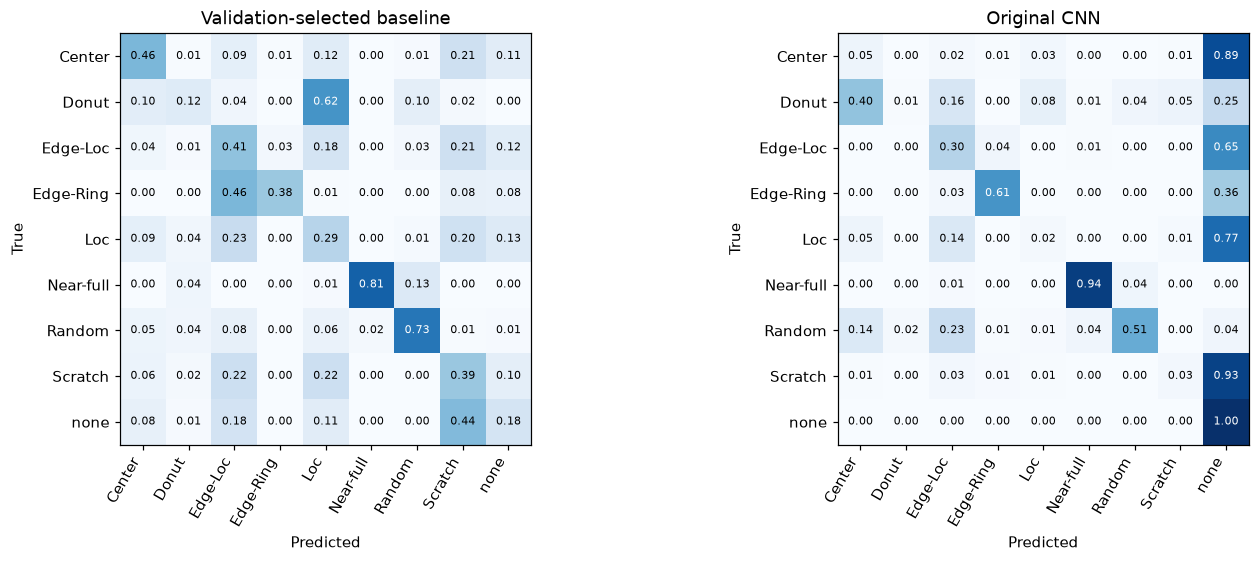

In [8]:
baseline_report=pd.read_csv(ROOT/"results"/"selected_baseline_classification_report.csv",index_col=0)
cnn_report=pd.read_csv(ROOT/"results"/"original_cnn_classification_report.csv",index_col=0)
perclass=pd.DataFrame({"baseline_F1":baseline_report.loc[CLASSES,"f1-score"],"CNN_F1":cnn_report.loc[CLASSES,"f1-score"],"baseline_recall":baseline_report.loc[CLASSES,"recall"],"CNN_recall":cnn_report.loc[CLASSES,"recall"],"support":baseline_report.loc[CLASSES,"support"].astype(int)})
perclass["F1_delta"]=perclass.baseline_F1-perclass.CNN_F1
perclass.to_csv(ROOT/"results"/"per_class_comparison.csv")
display(perclass.round(4))
ax=perclass[["baseline_F1","CNN_F1"]].plot.bar(figsize=(11,4),ylim=(0,1),rot=35)
ax.set_ylabel("Per-class F1");ax.set_title("Same held-out wafer maps");plt.tight_layout();plt.savefig(ROOT/"figures"/"05_class_f1.png",dpi=180);plt.show()
fig,axes=plt.subplots(1,2,figsize=(13,5),layout="constrained")
for ax,name,title in zip(axes,["selected_baseline","original_cnn"],["Validation-selected baseline","Original CNN"]):
    cm=np.load(ROOT/"results"/f"{name}_confusion.npy");cm=cm/cm.sum(1,keepdims=True)
    ax.imshow(cm,vmin=0,vmax=1,cmap="Blues")
    for i in range(9):
        for j in range(9):ax.text(j,i,f"{cm[i,j]:.2f}",ha="center",va="center",fontsize=7,color="white" if cm[i,j]>.55 else "black")
    ax.set_xticks(range(9),CLASSES,rotation=60,ha="right");ax.set_yticks(range(9),CLASSES)
    ax.set(xlabel="Predicted",ylabel="True",title=title)
fig.savefig(ROOT/"figures"/"06_confusion.png",dpi=180);plt.show()

### 9. 工程价值：先定义判断标准，再看结论

仅将验证集选出的全局候选与 CNN 比较。事先定义的最小纳入条件：测试 Macro F1 增加至少 0.03，配对 bootstrap 的 95% 区间下界大于 0，且平衡准确率提高。达到条件只说明值得加入**传统基线实验**，不代表替换 CNN 或部署上线。

Bootstrap 对同一组样本成对重采样；按类别分层以固定子集类别比例。区间只反映当前样本的不确定性，不涵盖训练随机性、批次相关性或工厂分布变化。延迟计时包含投影和分类，但不包含图像预处理和磁盘 I/O；没有相同条件下的 CNN 计时，不能声称比 CNN 快。

**新增的保守检查**：再按 lot 整批重采样，评估批次相关性对区间的影响。若批次区间不支持改善，也不加入原项目。

In [9]:
from src.study import fast_macro
prediction=pd.read_csv(ROOT/"results"/"test_predictions.csv")
matched=manifest.set_index("source_index").loc[prediction.source_index]
lot_ids=matched.lotName.to_numpy(); unique_lots=np.unique(lot_ids)
by_lot=[np.flatnonzero(lot_ids==lot) for lot in unique_lots]
y=prediction.true.to_numpy(); p=prediction.selected_baseline.to_numpy(); cnn=prediction.original_cnn.to_numpy()
rng=np.random.default_rng(CONFIG["seed"])
lot_boot=[]
for _ in range(2000):
    ix=np.concatenate([by_lot[i] for i in rng.integers(0,len(by_lot),size=len(by_lot))])
    lot_boot.append(fast_macro(y[ix],p[ix])-fast_macro(y[ix],cnn[ix]))
lot_ci=np.quantile(lot_boot,[.025,.975])
summary["lot_bootstrap_macro_f1_delta_ci95"]=lot_ci.tolist()
summary["integration_eligible"]=bool(summary["integration_eligible"] and lot_ci[0]>0)
summary["integration_scope"]="Add a documented classical baseline only if eligible; no CNN replacement."
(ROOT/"results"/"summary.json").write_text(json.dumps(summary,indent=2))
print("Macro F1 gain:",round(summary["macro_f1_delta"],4))
print("Sample-stratified 95% CI:",summary["macro_f1_delta_ci95"])
print("Lot-bootstrap 95% CI:",lot_ci)
print("Eligible to add baseline:",summary["integration_eligible"])
print("Warm baseline inference, ms/sample:",round(summary["inference_median_ms_per_sample"],3))
print("Saved model, MiB:",round((ROOT/"results"/"selected_baseline.joblib").stat().st_size/2**20,2))

Macro F1 gain: 0.0866
Sample-stratified 95% CI: [0.06359153841675334, 0.10993984963510521]
Lot-bootstrap 95% CI: [0.05959038 0.11216925]
Eligible to add baseline: True
Warm baseline inference, ms/sample: 0.008
Saved model, MiB: 1.85


### 10. 检查保存模型能否重现预测

保存的 joblib 包含所需的 PCA/LDA 变换、分类器和类别映射。这一检查是为了确保推理时不会漏掉中心化或投影，而不是重复寻找更高的测试分数。

In [10]:
import joblib
artifact=joblib.load(ROOT/"results"/"selected_baseline.joblib")
a=data["X_test"]
if artifact["pca"] is not None:a=artifact["pca"].transform(a)
if artifact["lda"] is not None:a=artifact["lda"].transform(a)
reproduced=artifact["classifier"].predict(a[:,:int(artifact["selection"]["dimension"])])
assert np.array_equal(reproduced,prediction.selected_baseline.to_numpy())
assert len(test_scores)==34 and len(validation_scores)==34
assert (test_scores[["accuracy","balanced_accuracy","macro_f1"]].to_numpy()>=0).all()
print("PASS: 34 fixed configurations; saved model reproduces every selected test prediction.")

PASS: 34 fixed configurations; saved model reproduces every selected test prediction.


### 11. 由真实结果自动生成的结论

下面严格使用验证候选的测试结果。曲线上的测试最优点只作描述，不用来宣称选出了一个可部署方案。

In [11]:
sel=summary["selected_on_validation"]
s=summary["selected_test"]; old=summary["cnn_common_test"]
family=pd.read_csv(ROOT/"results"/"common_test_comparison.csv")
lines=[f"- 验证集选定：**{sel['method']} + {sel['classifier']}，{int(sel['dimension'])} 维**。",
       f"- 相同测试子集上，候选 Accuracy={s['accuracy']:.2%}、Macro F1={s['macro_f1']:.4f}、Balanced Accuracy={s['balanced_accuracy']:.2%}。",
       f"- 原 CNN 在相同子集上，Accuracy={old['accuracy']:.2%}、Macro F1={old['macro_f1']:.4f}、Balanced Accuracy={old['balanced_accuracy']:.2%}。",
       f"- Macro F1 差值={summary['macro_f1_delta']:+.4f}；批次 bootstrap 95% 区间=[{lot_ci[0]:+.4f}, {lot_ci[1]:+.4f}]。"]
for clf in CONFIG['classifiers']:
    raw=family[(family.method=='Raw') & (family.classifier==clf)].iloc[0]
    for method in ['PCA','PCA+LDA']:
        row=family[(family.method==method)&(family.classifier==clf)].iloc[0]
        lines.append(f"- 固定 {clf}，{method} 的验证选定维数={int(row.dimension)}；相对不降维，测试准确率变化={(row.accuracy-raw.accuracy)*100:+.2f} 个百分点，Macro F1 变化={row.macro_f1-raw.macro_f1:+.4f}。")
lines += [
"- 跨集合泛化差距：候选验证 Macro F1 为 " + f"{sel['macro_f1']:.4f}" + "，测试下降到 " + f"{s['macro_f1']:.4f}" + "。差距很大，不能仅用类别比例解释；可能存在跨批次输入/类别条件分布差异或验证代表性不足，当前实验没有确定原因。",
"- 重要代价：候选对 none 的召回率为 " + f"{perclass.loc['none','baseline_recall']:.2%}" + "，CNN 为 " + f"{perclass.loc['none','CNN_recall']:.2%}" + "；新基线会产生较多正常晶圆误报，不适合直接替换原模型。",
"- 工程判断：" + ("满足预设条件，可作为独立的传统方法基线加入原项目；仍需全规模、跨批次验证。" if summary['integration_eligible'] else "未满足预设改善条件，不把新模型加入原项目。作业实验仍完整有效，负结果应保留。"),
"- 解释原则：PCA 的方差排序与缺陷判别目标不同；过强压缩可能丢失局部结构。LDA 最多 8 维，先做 PCA 的信息损失无法在 LDA 中恢复。具体类别的强弱以逐类表和混淆矩阵为准，不将合理机制猜测写成已证明因果。",
"- 限制：只有一次固定训练/验证划分，Near-full 验证样本少；CNN 训练数据量不同；测试集已被原项目观察；抽样比例不同于产线；图像缩放有损；bootstrap 不替代外部验证。"]
text='\n'.join(lines)
display(Markdown(text))
(ROOT/"results"/"conclusions_zh.md").write_text('# 实验结论\n\n'+text+'\n',encoding='utf-8')

- 验证集选定：**PCA + 3NN，16 维**。
- 相同测试子集上，候选 Accuracy=39.91%、Macro F1=0.4347、Balanced Accuracy=41.82%。
- 原 CNN 在相同子集上，Accuracy=35.95%、Macro F1=0.3481、Balanced Accuracy=38.57%。
- Macro F1 差值=+0.0866；批次 bootstrap 95% 区间=[+0.0596, +0.1122]。
- 固定 3NN，PCA 的验证选定维数=16；相对不降维，测试准确率变化=+12.50 个百分点，Macro F1 变化=+0.1410。
- 固定 3NN，PCA+LDA 的验证选定维数=7；相对不降维，测试准确率变化=+12.19 个百分点，Macro F1 变化=+0.1555。
- 固定 NCM，PCA 的验证选定维数=128；相对不降维，测试准确率变化=+0.19 个百分点，Macro F1 变化=+0.0009。
- 固定 NCM，PCA+LDA 的验证选定维数=8；相对不降维，测试准确率变化=-2.66 个百分点，Macro F1 变化=+0.0149。
- 跨集合泛化差距：候选验证 Macro F1 为 0.7990，测试下降到 0.4347。差距很大，不能仅用类别比例解释；可能存在跨批次输入/类别条件分布差异或验证代表性不足，当前实验没有确定原因。
- 重要代价：候选对 none 的召回率为 17.59%，CNN 为 100.00%；新基线会产生较多正常晶圆误报，不适合直接替换原模型。
- 工程判断：满足预设条件，可作为独立的传统方法基线加入原项目；仍需全规模、跨批次验证。
- 解释原则：PCA 的方差排序与缺陷判别目标不同；过强压缩可能丢失局部结构。LDA 最多 8 维，先做 PCA 的信息损失无法在 LDA 中恢复。具体类别的强弱以逐类表和混淆矩阵为准，不将合理机制猜测写成已证明因果。
- 限制：只有一次固定训练/验证划分，Near-full 验证样本少；CNN 训练数据量不同；测试集已被原项目观察；抽样比例不同于产线；图像缩放有损；bootstrap 不替代外部验证。

951

### 12. 文件与后续用途

- `results/validation_scores.csv`：全部验证结果。
- `results/frozen_selection.json`：测试前冻结的候选。
- `results/test_curves.csv`：固定维数网格的测试结果。
- `results/common_test_comparison.csv`：验证选维数后与原 CNN 的共同测试比较。
- `results/per_class_comparison.csv`：各类别表现。
- `results/test_predictions.csv`：原始索引及全部预测，便于复核。
- `results/summary.json`、`conclusions_zh.md`：结论与局限。
- `figures/`：所有图表。
- `results/selected_baseline.joblib`：可复现的候选推理模型。

完成这部分后，英文报告可以从实际图表和结果中整理；本 Notebook 不是最终提交报告。你仍需理解并检查方法与解释，符合老师对 AI 辅助使用的要求。
